# Challenge 2 — Modelo de Ising transversal y SQD

**Qiskit Fall Fest 2026 · Entrega en español**  
**Tema:** simulación de dinámica cuántica y diagonalización basada en muestras.

En este trabajo desarrollo las extensiones propuestas en el cuaderno **«Simulating Quantum Dynamics: The Transverse-Field Ising Model»**: estudio la magnetización, las correlaciones entre espines, el error frente al tamaño de paso, el costo de los circuitos y la diferencia entre Trotter de primer y segundo orden. Al final agrego el nivel intermedio: comparar distintas preparaciones iniciales para **SQD**, partiendo del método del primer laboratorio (*Sample, Then Diagonalize*).

**Cómo leerlo:** ejecutar las celdas en orden. Las comparaciones numéricas se hacen con NumPy/SciPy, lo cual es exacto o una simulación de las puertas para cuatro qubits. Si Qiskit está disponible, el cuaderno también construye los circuitos Qiskit y comprueba que coincidan con la simulación matricial. **No se afirma que se haya usado hardware cuántico real.**

**Créditos del material de partida:** Benjamin Tirado (BasQ Qiskit Fall Fest 2026), con aportes de Mauricio Gutiérrez (UCR, EnLuz Qiskit Fall Fest 2026). Su material original se conserva como fuente y se reconoce al final.

## 1. Preparación del entorno

El archivo es un Notebook `.ipynb` compatible con Google Colab desde una tablet. La primera celda instala Qiskit si falta **y estamos en Colab**. En un entorno sin conexión a Internet, los resultados numéricos siguen siendo reproducibles gracias a una implementación equivalente con matrices de NumPy/SciPy; en ese caso, las validaciones específicas de Qiskit quedan identificadas como pendientes de ejecutar en Colab.

In [1]:
import sys
import importlib.util
import subprocess

# En Colab puedo instalar Qiskit sin utilizar una terminal o Visual Studio Code.
es_colab = "google.colab" in sys.modules
if es_colab and importlib.util.find_spec("qiskit") is None:
    print("Preparando Qiskit en Google Colab...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "qiskit==2.5.2", "pylatexenc==2.11"
    ])
elif importlib.util.find_spec("qiskit") is None:
    print("Qiskit no está instalado aquí; se usará el cálculo matricial verificable.")
else:
    print("Qiskit ya está instalado.")

Qiskit no está instalado aquí; se usará el cálculo matricial verificable.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

try:
    from qiskit import QuantumCircuit, transpile
    from qiskit.circuit.library import PauliEvolutionGate
    from qiskit.synthesis import LieTrotter, SuzukiTrotter
    from qiskit.quantum_info import SparsePauliOp, Statevector
    from qiskit.primitives import StatevectorEstimator, StatevectorSampler
    import qiskit
    QISKIT_DISPONIBLE = True
    print("Qiskit disponible:", qiskit.__version__)
except ImportError:
    QISKIT_DISPONIBLE = False
    print("Qiskit pendiente de comprobar en Colab; cálculos con NumPy/SciPy disponibles.")

np.set_printoptions(precision=6, suppress=True)

Qiskit pendiente de comprobar en Colab; cálculos con NumPy/SciPy disponibles.


## 2. Hamiltoniano: ¿qué sistema estoy simulando?

Trabajo con una **cadena abierta de cuatro espines**, con intensidad de interacción $J=1$ y campo transversal $h=1$. El Hamiltoniano del cuaderno original es

$$H=-J\sum_{i=0}^{N-2} Z_i Z_{i+1}-h\sum_{i=0}^{N-1}X_i.$$

Los términos $ZZ$ favorecen alineaciones y los $X$ pueden cambiar el estado de los espines. A diferencia de los términos dentro de cada grupo, **los grupos $H_{ZZ}$ y $H_X$ no conmutan en general**. Por eso separar la evolución en puertas elementales introduce un error que hay que analizar.

Uso el convenio de Qiskit: **`q0` es el bit de la derecha**. Para tener un control independiente, construyo las matrices del Hamiltoniano con productos de Kronecker y, si Qiskit está disponible, también con `SparsePauliOp`.

In [3]:
N = 4
J = 1.0
h = 1.0

I2 = np.eye(2, dtype=complex)
X2 = np.array([[0, 1], [1, 0]], dtype=complex)
Z2 = np.diag([1, -1]).astype(complex)
PAULIS = {"I": I2, "X": X2, "Z": Z2}

def operador_pauli(operadores, n=N):
    """Construyo la matriz de una cadena de Paulis, con q0 a la derecha."""
    resultado = np.array([[1]], dtype=complex)
    for qubit in range(n - 1, -1, -1):
        resultado = np.kron(resultado, PAULIS[operadores.get(qubit, "I")])
    return resultado

def etiqueta_pauli(operadores, n=N):
    """Devuelvo la cadena en el orden que utiliza Qiskit."""
    return "".join(operadores.get(qubit, "I") for qubit in range(n - 1, -1, -1))

# Separo el Hamiltoniano en dos grupos para estudiar Trotter.
H_ZZ = sum((-J * operador_pauli({i: "Z", i + 1: "Z"}) for i in range(N - 1)),
           np.zeros((2**N, 2**N), dtype=complex))
H_X = sum((-h * operador_pauli({i: "X"}) for i in range(N)),
          np.zeros((2**N, 2**N), dtype=complex))
H = H_ZZ + H_X

# Magnetización media por sitio, igual a la definida en la práctica original.
M_Z = sum((operador_pauli({i: "Z"}) / N for i in range(N)),
          np.zeros_like(H))

# Estado inicial: todos los qubits en |0>.
psi_inicial = np.zeros(2**N, dtype=complex)
psi_inicial[0] = 1.0

if QISKIT_DISPONIBLE:
    terminos = [(etiqueta_pauli({i: "Z", i+1: "Z"}), -J) for i in range(N-1)]
    terminos += [(etiqueta_pauli({i: "X"}), -h) for i in range(N)]
    H_qiskit = SparsePauliOp.from_list(terminos)
    M_qiskit = SparsePauliOp.from_list([
        (etiqueta_pauli({i: "Z"}), 1 / N) for i in range(N)
    ])
    assert np.allclose(H_qiskit.to_matrix(), H)
    assert np.allclose(M_qiskit.to_matrix(), M_Z)

assert np.allclose(H, H.conj().T), "El Hamiltoniano debe ser hermítico."
assert H.shape == (16, 16)
print("Número de qubits:", N)
print("Dimensión del Hamiltoniano:", H.shape)
print("Términos ZZ:", N - 1, "| Términos X:", N)
print("Magnetización inicial:", np.vdot(psi_inicial, M_Z @ psi_inicial).real)

Número de qubits: 4
Dimensión del Hamiltoniano: (16, 16)
Términos ZZ: 3 | Términos X: 4
Magnetización inicial: 1.0


## 3. Evolución exacta y evolución aproximada por Trotter

La evolución cuántica cumple $|\psi(t)\rangle=e^{-iHt}|\psi(0)\rangle$. Para cuatro qubits puedo calcular la exponencial exacta usando SciPy. En sistemas grandes esto deja de ser práctico.

Para aplicar puertas en lugar de una matriz general, utilizo pasos $\Delta t=t/n$. La **versión de primer orden** aplica una capa $ZZ$ y después una capa $X$ en cada paso; la **versión simétrica de segundo orden** aplica media capa $ZZ$, una capa $X$ y media capa $ZZ$. Importante: en la multiplicación de matrices la primera capa que actúa sobre el vector queda a la derecha.

$$U_{\mathrm{Lie}}(\Delta t)=e^{-iH_X\Delta t}e^{-iH_{ZZ}\Delta t},$$
$$U_{\mathrm{Suzuki2}}(\Delta t)=e^{-iH_{ZZ}\Delta t/2}e^{-iH_X\Delta t}e^{-iH_{ZZ}\Delta t/2}.$$

En Qiskit usaré `PauliEvolutionGate`, `LieTrotter` y `SuzukiTrotter` con los mismos parámetros.

In [4]:
def estado_exacto(t):
    """Referencia clásica: evolución mediante exponencial del Hamiltoniano completo."""
    return expm(-1j * H * t) @ psi_inicial

def estado_trotter_matriz(t, pasos, orden=1):
    """Simulo las capas ZZ y X usando matrices; orden 1 o 2."""
    if pasos < 1:
        if np.isclose(t, 0.0):
            return psi_inicial.copy()
        raise ValueError("Para t > 0 necesito al menos un paso.")
    dt = t / pasos
    ux = expm(-1j * H_X * dt)
    if orden == 1:
        uz = expm(-1j * H_ZZ * dt)
        paso = ux @ uz  # Primero actúa ZZ, luego X.
    elif orden == 2:
        uz_medio = expm(-1j * H_ZZ * dt / 2)
        paso = uz_medio @ ux @ uz_medio
    else:
        raise ValueError("Solo se comparan los órdenes 1 y 2.")
    return np.linalg.matrix_power(paso, pasos) @ psi_inicial

def circuito_trotter(t, pasos, orden=1):
    """Construyo el circuito Qiskit que implementa la misma fórmula de producto."""
    if not QISKIT_DISPONIBLE:
        raise RuntimeError("La parte de Qiskit se ejecuta en Colab.")
    circuito = QuantumCircuit(N)
    if pasos == 0:
        return circuito
    if orden == 1:
        sintetizador = LieTrotter(reps=pasos)
    elif orden == 2:
        sintetizador = SuzukiTrotter(order=2, reps=pasos)
    else:
        raise ValueError("Orden no reconocido.")
    circuito.append(PauliEvolutionGate(H_qiskit, time=float(t),
                                        synthesis=sintetizador), range(N))
    return circuito

def promedio(estado, operador):
    """Calculo el valor esperado real de un observable hermítico."""
    return float(np.real(np.vdot(estado, operador @ estado)))

# Comprobaciones matemáticas que no requieren conexión a internet.
for orden in (1, 2):
    psi = estado_trotter_matriz(t=1.0, pasos=10, orden=orden)
    assert np.isclose(np.linalg.norm(psi), 1.0)
    print(f"Orden {orden}: norma del estado = {np.linalg.norm(psi):.10f}")

# Esta comparación se ejecuta si tengo Qiskit instalado.
if QISKIT_DISPONIBLE:
    for orden in (1, 2):
        psi_q = Statevector.from_instruction(circuito_trotter(1.0, 10, orden)).data
        psi_np = estado_trotter_matriz(1.0, 10, orden)
        coincidencia = abs(np.vdot(psi_q, psi_np))**2
        print(f"Orden {orden}: fidelidad Qiskit vs matrices = {coincidencia:.10f}")
        assert np.isclose(coincidencia, 1, atol=1e-9)
else:
    print("Verificación de circuitos Qiskit: pendiente de ejecutar en Colab.")

Orden 1: norma del estado = 1.0000000000
Orden 2: norma del estado = 1.0000000000
Verificación de circuitos Qiskit: pendiente de ejecutar en Colab.


## 4. Magnetización en función del tiempo

Reproduzco el experimento central del cuaderno original: $N=4$, $J=h=1$, paso $\Delta t=0.2$ y una trayectoria hasta $t=6$. Comparo la magnetización aproximada con una referencia exacta.

$$M_z(t)=\frac1N\sum_i\langle Z_i\rangle.$$

El error representado es $|M_z^{\mathrm{Trotter}}-M_z^{\mathrm{exacta}}|$. La matriz da resultados sin ruido de shots. Además, cuando Qiskit está disponible, compruebo algunos puntos directamente con `StatevectorEstimator`.

In [5]:
dt = 0.2
pasos_maximos = 30
tiempos = np.arange(pasos_maximos + 1) * dt

magnetizacion_exacta = np.array([promedio(estado_exacto(t), M_Z) for t in tiempos])
magnetizacion_trotter = np.array([
    promedio(estado_trotter_matriz(float(t), pasos, 1), M_Z)
    for pasos, t in enumerate(tiempos)
])
error_magnetizacion = np.abs(magnetizacion_trotter - magnetizacion_exacta)

assert np.isclose(magnetizacion_exacta[0], 1.0)
assert np.isclose(magnetizacion_trotter[0], 1.0)
print("Error absoluto máximo a lo largo de la trayectoria:", round(error_magnetizacion.max(), 6))
print("Error absoluto en t=6:", round(error_magnetizacion[-1], 6))

if QISKIT_DISPONIBLE:
    estimador = StatevectorEstimator()
    for pasos in (5, 10):
        circuito = circuito_trotter(pasos * dt, pasos, orden=1)
        ev = float(estimador.run([(circuito, M_qiskit)]).result()[0].data.evs)
        print(f"Qiskit Estimator, t={pasos * dt:.1f}: {ev:.8f}")
        assert np.isclose(ev, magnetizacion_trotter[pasos], atol=1e-8)

Error absoluto máximo a lo largo de la trayectoria: 0.071429
Error absoluto en t=6: 0.052333


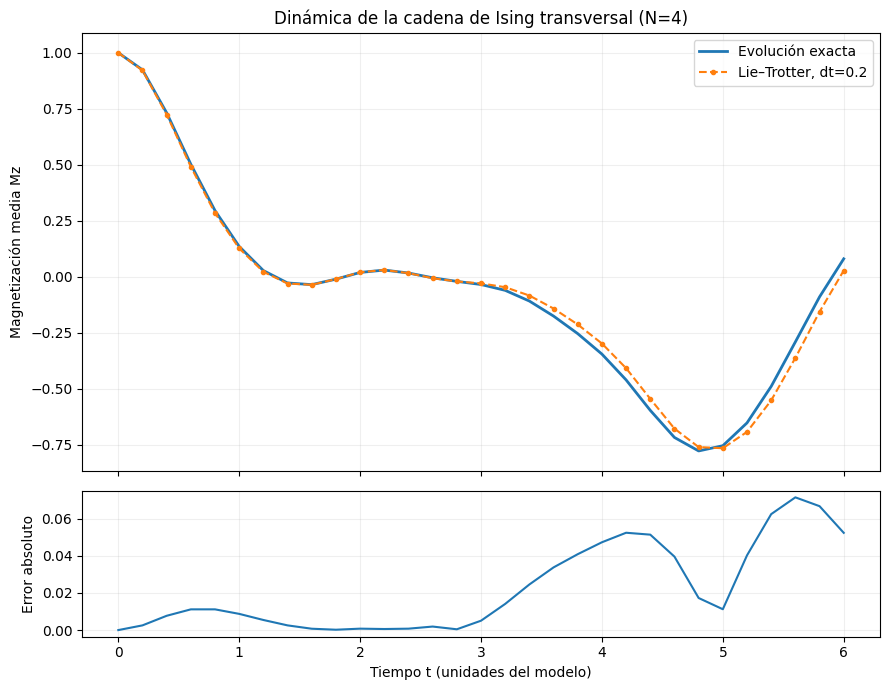

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(tiempos, magnetizacion_exacta, label="Evolución exacta", lw=2)
ax1.plot(tiempos, magnetizacion_trotter, "o--", ms=3,
         label="Lie–Trotter, dt=0.2")
ax1.set_ylabel("Magnetización media Mz")
ax1.set_title("Dinámica de la cadena de Ising transversal (N=4)")
ax1.legend()
ax1.grid(alpha=0.2)
ax2.plot(tiempos, error_magnetizacion)
ax2.set_xlabel("Tiempo t (unidades del modelo)")
ax2.set_ylabel("Error absoluto")
ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Reto de principiante: correlaciones entre espines

No basta con mirar la magnetización de cada espín por separado. También podemos estudiar cuánto se relacionan los resultados de dos sitios $i,j$. La **correlación conectada** es

$$C_{ij}(t)=\langle Z_i Z_j\rangle-\langle Z_i\rangle\langle Z_j\rangle.$$

La diferencia evita confundir una correlación real con el simple producto de las magnetizaciones individuales. Calculo el promedio de $C_{ij}$ para parejas separadas por distancia 1, 2 y 3, primero con el estado exacto y después con Trotter.

Correlaciones conectadas iniciales (deben ser cero):
 tiempo  distancia  C_exacta  C_trotter
    0.0          1       0.0        0.0
    0.0          2       0.0        0.0
    0.0          3       0.0        0.0


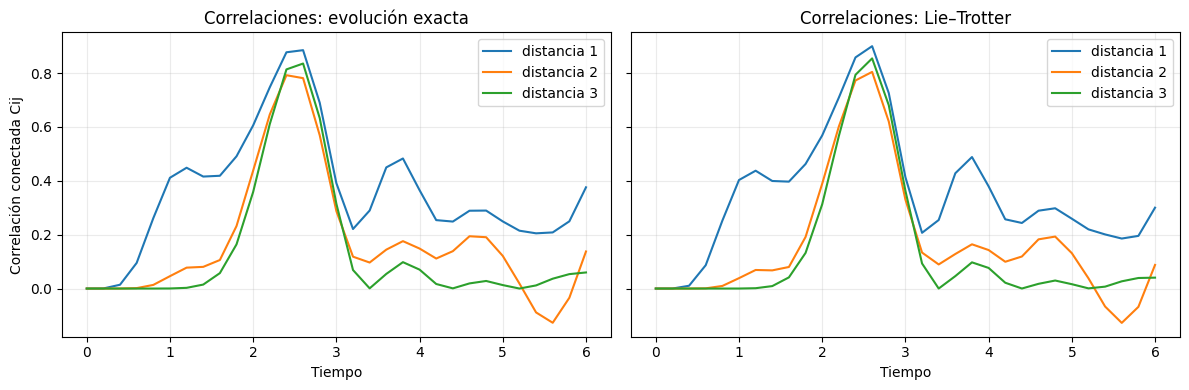

In [7]:
def correlaciones_por_distancia(estado):
    """Promedio de las correlaciones conectadas para cada distancia."""
    z = [promedio(estado, operador_pauli({i: "Z"})) for i in range(N)]
    por_distancia = {}
    for separacion in range(1, N):
        pares = []
        for i in range(N - separacion):
            j = i + separacion
            zz = promedio(estado, operador_pauli({i: "Z", j: "Z"}))
            pares.append(zz - z[i] * z[j])
        por_distancia[separacion] = float(np.mean(pares))
    return por_distancia

# Registro la evolución para todos los puntos del barrido original.
corr_exactas = [correlaciones_por_distancia(estado_exacto(float(t))) for t in tiempos]
corr_trotter = [correlaciones_por_distancia(
    estado_trotter_matriz(float(t), k, orden=1)) for k, t in enumerate(tiempos)]

tabla_correlacion = pd.DataFrame([
    {"tiempo": float(t), "distancia": d,
     "C_exacta": corr_exactas[k][d], "C_trotter": corr_trotter[k][d]}
    for k, t in enumerate(tiempos) for d in range(1, N)
])
print("Correlaciones conectadas iniciales (deben ser cero):")
print(tabla_correlacion.head(3).to_string(index=False))
assert np.allclose(tabla_correlacion.head(3)["C_exacta"], 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for d in range(1, N):
    datos = tabla_correlacion[tabla_correlacion["distancia"] == d]
    ax1.plot(datos["tiempo"], datos["C_exacta"], label=f"distancia {d}")
    ax2.plot(datos["tiempo"], datos["C_trotter"], label=f"distancia {d}")
ax1.set_title("Correlaciones: evolución exacta")
ax2.set_title("Correlaciones: Lie–Trotter")
for ax in (ax1, ax2):
    ax.set_xlabel("Tiempo")
    ax.grid(alpha=0.25)
    ax.legend()
ax1.set_ylabel("Correlación conectada Cij")
plt.tight_layout()
plt.show()

**Interpretación de las correlaciones.** Al principio $|0000\rangle$ es un estado producto, por eso $C_{ij}(0)=0$. Durante la evolución las interacciones y el campo generan correlaciones. La comparación entre las tres distancias permite observar si los sitios más alejados adquieren correlaciones más tarde o con distinta intensidad. Aquí solo hay cuatro sitios: estos resultados ilustran el fenómeno, pero no prueban una ley universal de propagación de información.

## 6. Tamaño de paso: precisión frente a costo

Para comparar pasos de manera justa, **mantengo fijo el tiempo final $T=1$** y cambio el número de pasos. Si $n$ aumenta, $\Delta t=T/n$ disminuye. Analizo tanto el error de magnetización como la diferencia entre los estados cuánticos.

Una medida útil es la **infidelidad**: $1-|\langle\psi_{\mathrm{exacta}}|\psi_{\mathrm{Trotter}}\rangle|^2$. Vale cero cuando los estados coinciden hasta una fase global. Es importante distinguirla del error de un observable: dos estados distintos pueden producir el mismo valor de magnetización.

,orden,pasos,dt,error_Mz,infidelidad,puertas_ZZ_logicas
0,1,2,0.500000,0.064609,1.604509e-01,6
1,1,4,0.250000,0.013870,3.290000e-02,12
2,1,6,0.166667,0.006003,1.400870e-02,18
3,1,8,0.125000,0.003346,7.752500e-03,24
4,1,12,0.083333,0.001478,3.402100e-03,36
5,1,20,0.050000,0.000530,1.215700e-03,60
6,1,40,0.025000,0.000132,3.027000e-04,120
7,2,2,0.500000,0.064609,4.778570e-02,12
8,2,4,0.250000,0.013870,2.494200e-03,24
9,2,6,0.166667,0.006003,4.760000e-04,36


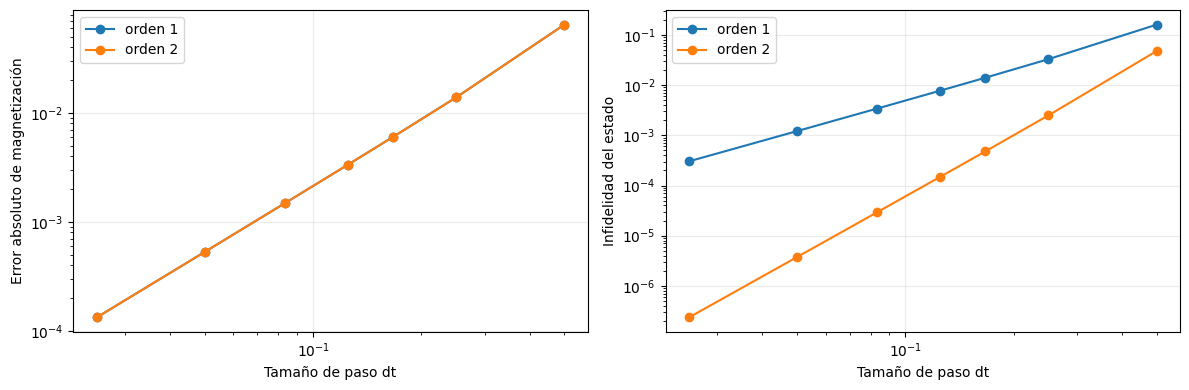

In [8]:
T_FINAL = 1.0
pasos_analisis = [2, 4, 6, 8, 12, 20, 40]
psi_referencia = estado_exacto(T_FINAL)
valor_referencia = promedio(psi_referencia, M_Z)

def infidelidad(estado, referencia):
    return float(max(0.0, 1 - abs(np.vdot(referencia, estado))**2))

filas = []
for orden in (1, 2):
    for pasos in pasos_analisis:
        psi = estado_trotter_matriz(T_FINAL, pasos, orden)
        filas.append({
            "orden": orden,
            "pasos": pasos,
            "dt": T_FINAL / pasos,
            "error_Mz": abs(promedio(psi, M_Z) - valor_referencia),
            "infidelidad": infidelidad(psi, psi_referencia),
            "puertas_ZZ_logicas": (N - 1) * pasos * (1 if orden == 1 else 2),
        })
resultados_pasos = pd.DataFrame(filas)
display(resultados_pasos.round(7))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for orden, grupo in resultados_pasos.groupby("orden"):
    a1.loglog(grupo["dt"], grupo["error_Mz"], "o-", label=f"orden {orden}")
    a2.loglog(grupo["dt"], grupo["infidelidad"], "o-", label=f"orden {orden}")
a1.set_xlabel("Tamaño de paso dt")
a1.set_ylabel("Error absoluto de magnetización")
a2.set_xlabel("Tamaño de paso dt")
a2.set_ylabel("Infidelidad del estado")
for ax in (a1, a2):
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

### Un resultado que merece atención

En este ejemplo concreto, las magnetizaciones de primer y segundo orden pueden coincidir casi exactamente, **aunque los estados cuánticos no coincidan igual de bien**. Esto no significa que segundo orden sea inútil: para el estado inicial $|0000\rangle$ y el observable diagonal $M_z$, las evoluciones de ambos esquemas están relacionadas por una rotación diagonal de borde que no afecta esa medición. Por eso agregué **infidelidad de estado**, que sí permite ver la diferencia entre fórmulas.

No sería correcto concluir que Suzuki siempre reduce el error de cualquier observable, ni que siempre cuesta menos. La precisión y el costo dependen del estado, del observable, del tiempo y de los pasos escogidos.

## 7. Profundidad de circuito y puertas de dos qubits

Para estudiar el costo, distingo entre **puertas ZZ lógicas** y **puertas CX físicas después de descomponer el circuito**. La segunda cifra depende de la elección de puertas base y del transpiler, así que solo la reporto cuando Qiskit está disponible. En todos los casos utilizo una comparación consistente, sin ruido y con cuatro qubits.

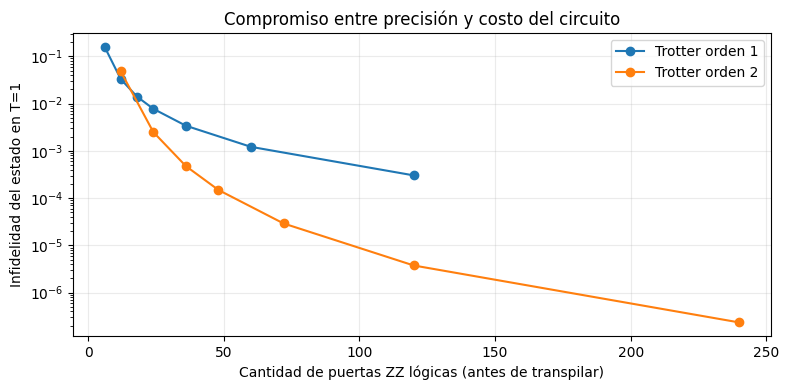

La profundidad y el conteo de CX quedan pendientes para Colab con Qiskit.
La gráfica superior sí utiliza el costo lógico calculado y validado.


In [9]:
# Relación entre error de estado y número de bloques ZZ lógicos.
fig, ax = plt.subplots(figsize=(8, 4))
for orden, grupo in resultados_pasos.groupby("orden"):
    ax.semilogy(grupo["puertas_ZZ_logicas"], grupo["infidelidad"],
                "o-", label=f"Trotter orden {orden}")
ax.set_xlabel("Cantidad de puertas ZZ lógicas (antes de transpilar)")
ax.set_ylabel("Infidelidad del estado en T=1")
ax.set_title("Compromiso entre precisión y costo del circuito")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

if QISKIT_DISPONIBLE:
    datos_circuito = []
    for orden in (1, 2):
        for pasos in pasos_analisis:
            circuito = circuito_trotter(T_FINAL, pasos, orden)
            compilado = transpile(circuito,
                                  basis_gates=["rx", "rz", "cx", "h", "sx", "x"],
                                  optimization_level=0)
            datos_circuito.append({"orden": orden, "pasos": pasos,
                                   "profundidad": compilado.depth(),
                                   "puertas_cx": compilado.count_ops().get("cx", 0)})
    tabla_circuitos = pd.DataFrame(datos_circuito)
    print("Conteos reales de puertas obtenidos con Qiskit (sin optimización):")
    display(tabla_circuitos)
else:
    print("La profundidad y el conteo de CX quedan pendientes para Colab con Qiskit.")
    print("La gráfica superior sí utiliza el costo lógico calculado y validado.")

## 8. Nivel intermedio — SQD con estados iniciales diferentes

Esta parte se basa en el primer laboratorio *Sample, Then Diagonalize*. Allí partimos de una preparación tipo GHZ y utilizamos las cadenas medidas para recortar el Hamiltoniano. Aquí pruebo **varias familias de circuitos**: una GHZ sin rotaciones, una GHZ con rotaciones RY, un producto de rotaciones RY, dos pares Bell y una estructura con H/CX/RY.

La regla SQD que utilizo en este experimento didáctico es:

1. Preparar un estado cuántico aproximado.
2. Tomar un número fijo de muestras en la base computacional.
3. Conservar las **cadenas diferentes** que aparecieron.
4. Recortar la matriz de $H$ a esos índices y diagonalizar el bloque.
5. Comparar la menor energía del bloque con la del Hamiltoniano completo.

La diagonalización del subespacio vuelve a optimizar los coeficientes del estado; **no reutiliza las amplitudes del circuito**. Mantengo el mismo número de shots y semillas comparables entre familias. Todo se simula sin ruido de hardware.

In [10]:
# Estas operaciones matriciales permiten validar las preparaciones incluso sin Qiskit.
PUERTA_H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

def puerta_ry(angulo):
    return np.array([[np.cos(angulo/2), -np.sin(angulo/2)],
                     [np.sin(angulo/2),  np.cos(angulo/2)]], dtype=complex)

def aplicar_un_qubit(estado, puerta, qubit):
    """Aplico una puerta 2x2 conservando el orden de bits de Qiskit."""
    salida = np.zeros_like(estado)
    mascara = 1 << qubit
    for indice, amplitud in enumerate(estado):
        bit_entrada = int(bool(indice & mascara))
        base = indice & ~mascara
        salida[base] += puerta[0, bit_entrada] * amplitud
        salida[base | mascara] += puerta[1, bit_entrada] * amplitud
    return salida

def aplicar_cx(estado, control, objetivo):
    """Aplico CX intercambiando los índices donde el control vale 1."""
    salida = np.zeros_like(estado)
    for indice, amplitud in enumerate(estado):
        destino = indice ^ (1 << objetivo) if indice & (1 << control) else indice
        salida[destino] += amplitud
    return salida

FAMILIAS = ["GHZ", "GHZ + RY", "Producto RY", "Dos Bell + RY", "Capas H/CX/RY"]

def estado_ansatz_numpy(familia, angulo=0.35):
    """Preparo el estado del ansatz usando matrices y operaciones explícitas."""
    psi = psi_inicial.copy()
    if familia in ("GHZ", "GHZ + RY"):
        psi = aplicar_un_qubit(psi, PUERTA_H, 0)
        for i in range(N - 1):
            psi = aplicar_cx(psi, i, i + 1)
        if familia == "GHZ + RY":
            for i in range(N):
                psi = aplicar_un_qubit(psi, puerta_ry(angulo), i)
    elif familia == "Producto RY":
        for i in range(N):
            psi = aplicar_un_qubit(psi, puerta_ry(angulo), i)
    elif familia == "Dos Bell + RY":
        for control, objetivo in ((0, 1), (2, 3)):
            psi = aplicar_un_qubit(psi, PUERTA_H, control)
            psi = aplicar_cx(psi, control, objetivo)
        for i in range(N):
            psi = aplicar_un_qubit(psi, puerta_ry(angulo), i)
    elif familia == "Capas H/CX/RY":
        psi = aplicar_un_qubit(psi, PUERTA_H, 0)
        psi = aplicar_un_qubit(psi, PUERTA_H, 2)
        psi = aplicar_cx(psi, 0, 1)
        psi = aplicar_cx(psi, 2, 3)
        psi = aplicar_cx(psi, 1, 2)
        for i in range(N):
            psi = aplicar_un_qubit(psi, puerta_ry(angulo), i)
    else:
        raise ValueError("Familia no reconocida.")
    return psi

def circuito_ansatz(familia, angulo=0.35):
    """Equivalente en puertas de Qiskit (para Colab y muestreo)."""
    if not QISKIT_DISPONIBLE:
        raise RuntimeError("Ejecutar en Colab para obtener circuitos Qiskit.")
    qc = QuantumCircuit(N)
    if familia in ("GHZ", "GHZ + RY"):
        qc.h(0)
        for i in range(N - 1): qc.cx(i, i + 1)
        if familia == "GHZ + RY":
            for i in range(N): qc.ry(angulo, i)
    elif familia == "Producto RY":
        for i in range(N): qc.ry(angulo, i)
    elif familia == "Dos Bell + RY":
        for c, o in ((0, 1), (2, 3)):
            qc.h(c)
            qc.cx(c, o)
        for i in range(N): qc.ry(angulo, i)
    elif familia == "Capas H/CX/RY":
        qc.h(0); qc.h(2)
        qc.cx(0, 1); qc.cx(2, 3); qc.cx(1, 2)
        for i in range(N): qc.ry(angulo, i)
    else:
        raise ValueError("Familia no reconocida.")
    return qc

for familia in FAMILIAS:
    estado = estado_ansatz_numpy(familia, 0.35)
    assert np.isclose(np.linalg.norm(estado), 1)
    if QISKIT_DISPONIBLE:
        estado_q = Statevector(circuito_ansatz(familia, 0.35)).data
        assert np.allclose(estado, estado_q, atol=1e-10)
print("Las cinco preparaciones conservan la norma del estado.")

if QISKIT_DISPONIBLE:
    # Una demostración real del Sampler de Qiskit. El resto utiliza
    # muestreo NumPy equivalente para repetir muchos experimentos rápidamente.
    circuito_medible = circuito_ansatz("GHZ + RY", 0.35)
    circuito_medible.measure_all()
    muestras_qiskit = StatevectorSampler(seed=7).run(
        [circuito_medible], shots=24
    ).result()[0].data.meas.get_counts()
    print("Ejemplo de cadenas medidas con Qiskit:", muestras_qiskit)

Las cinco preparaciones conservan la norma del estado.


Energía fundamental exacta (referencia): -4.75877048
Cada prueba SQD utilizó 12 shots; 40 repeticiones por familia.


,familia,error_circuito,error_SQD_medio,error_SQD_desv,configuraciones_medias
0,GHZ,1.75877,1.75877,0.00000,2.000
1,GHZ + RY,2.11151,1.39937,0.25582,3.475
2,Producto RY,0.57669,0.85256,0.31737,7.175
3,Dos Bell + RY,2.75877,1.75877,0.00000,3.925
4,Capas H/CX/RY,3.75877,1.50252,0.57835,5.375


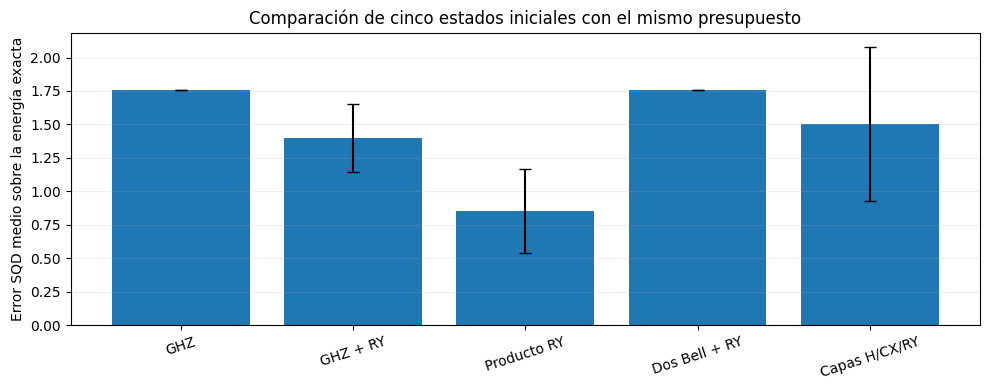

Menor error SQD medio en este experimento: Producto RY
Error SQD medio: 0.852557


In [11]:
# Referencia exacta del estado fundamental del Hamiltoniano completo.
energia_fundamental = float(np.linalg.eigvalsh(H)[0])

def energia_sqd(estado, shots=12, semilla=7):
    """Muestreo, selecciono cadenas distintas y diagonalizo el bloque de H."""
    probabilidades = np.abs(estado) ** 2
    probabilidades = probabilidades / probabilidades.sum()
    rng = np.random.default_rng(semilla)
    medidas = rng.choice(2**N, size=shots, p=probabilidades)
    configuraciones = np.unique(medidas)
    submatriz = H[np.ix_(configuraciones, configuraciones)]
    energia = float(np.linalg.eigvalsh(submatriz)[0])
    assert energia >= energia_fundamental - 1e-9  # Principio variacional.
    return energia, len(configuraciones)

SHOTS_SQD = 12
REPETICIONES = 40
filas_sqd = []
for familia in FAMILIAS:
    angulo = 1.10 if familia == "Producto RY" else 0.35
    estado = estado_ansatz_numpy(familia, angulo)
    energia_circuito = promedio(estado, H)
    for repeticion in range(REPETICIONES):
        energia, cantidad = energia_sqd(estado, shots=SHOTS_SQD,
                                       semilla=2026 + repeticion)
        filas_sqd.append({
            "familia": familia,
            "repeticion": repeticion,
            "shots": SHOTS_SQD,
            "configuraciones": cantidad,
            "error_energia_circuito": energia_circuito - energia_fundamental,
            "error_energia_sqd": energia - energia_fundamental,
        })

resultados_sqd = pd.DataFrame(filas_sqd)
resumen_sqd = (resultados_sqd.groupby("familia", sort=False)
               .agg(error_circuito=("error_energia_circuito", "mean"),
                    error_SQD_medio=("error_energia_sqd", "mean"),
                    error_SQD_desv=("error_energia_sqd", "std"),
                    configuraciones_medias=("configuraciones", "mean"))
               .reset_index())
print(f"Energía fundamental exacta (referencia): {energia_fundamental:.8f}")
print(f"Cada prueba SQD utilizó {SHOTS_SQD} shots; {REPETICIONES} repeticiones por familia.")
display(resumen_sqd.round(5))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(resumen_sqd["familia"], resumen_sqd["error_SQD_medio"],
       yerr=resumen_sqd["error_SQD_desv"], capsize=4)
ax.set_ylabel("Error SQD medio sobre la energía exacta")
ax.set_title("Comparación de cinco estados iniciales con el mismo presupuesto")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

mejor = resumen_sqd.loc[resumen_sqd["error_SQD_medio"].idxmin()]
print("Menor error SQD medio en este experimento:", mejor["familia"])
print("Error SQD medio:", round(float(mejor["error_SQD_medio"]), 6))

### 8.1. Una manera sistemática de elegir la preparación

Una comparación justa exige repetir los experimentos y controlar el presupuesto. Para no elegir un circuito solo por una medición afortunada, exploro un **barrido de ángulos RY** dentro de una familia. Distingo entre la energía del estado preparado y la energía de SQD: **son medidas diferentes**.

Este barrido es una exploración didáctica en simulación clásica pequeña. En hardware real necesitaríamos medir la energía del ansatz en bases adecuadas, y la elección de hiperparámetros requeriría pruebas independientes para no sobreajustar las semillas.

,angulo,error_circuito,error_SQD_medio,configuraciones_medias
0,0.00,1.758770,1.758770,2.00
1,0.15,1.825766,1.723317,2.12
2,0.35,2.111507,1.459443,3.36
3,0.60,2.715234,1.274749,5.12
4,1.00,3.882991,1.141229,7.52
5,1.40,4.672104,1.703348,6.60


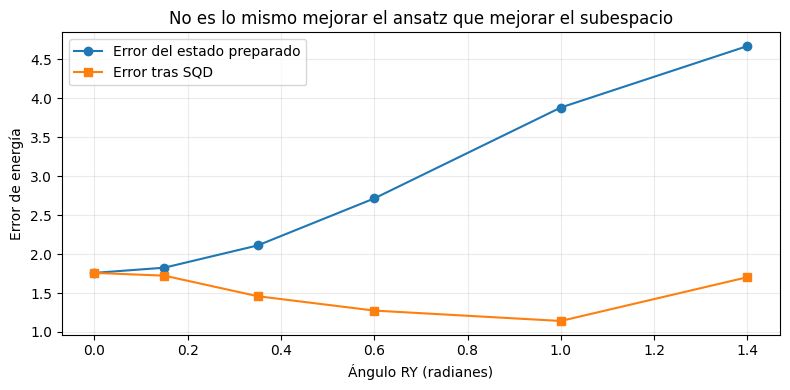

In [12]:
angulos = [0.0, 0.15, 0.35, 0.6, 1.0, 1.4]
filas_barrido = []
for angulo in angulos:
    estado = estado_ansatz_numpy("GHZ + RY", angulo)
    errores = []
    cantidades = []
    for i in range(25):
        energia, distintas = energia_sqd(estado, shots=SHOTS_SQD,
                                         semilla=4000 + i)
        errores.append(energia - energia_fundamental)
        cantidades.append(distintas)
    filas_barrido.append({
        "angulo": angulo,
        "error_circuito": promedio(estado, H) - energia_fundamental,
        "error_SQD_medio": float(np.mean(errores)),
        "configuraciones_medias": float(np.mean(cantidades)),
    })
barrido = pd.DataFrame(filas_barrido)
display(barrido.round(6))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(barrido["angulo"], barrido["error_circuito"], "o-",
        label="Error del estado preparado")
ax.plot(barrido["angulo"], barrido["error_SQD_medio"], "s-",
        label="Error tras SQD")
ax.set_xlabel("Ángulo RY (radianes)")
ax.set_ylabel("Error de energía")
ax.set_title("No es lo mismo mejorar el ansatz que mejorar el subespacio")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Conclusiones

**Dinámica y correlaciones.** La magnetización muestra una evolución oscilatoria y las correlaciones conectadas revelan información que no aparece en un promedio de un solo qubit. La simulación exacta permite comprobar la calidad de la aproximación sin usar el resultado de referencia como entrada del circuito.

**Trotter y profundidad.** Al reducir $\Delta t$ normalmente mejora la aproximación, pero hay que aplicar más puertas. En este caso, el error de la **magnetización** coincide para dos órdenes de Trotter en varios puntos del barrido; por eso también medí **infidelidad del estado**, donde sí se observa la diferencia. No debo usar un solo observable para afirmar que dos métodos son igual de precisos en general.

**SQD y estados iniciales.** El circuito produce candidatos; la diagonalización del bloque seleccionado calcula de nuevo los coeficientes óptimos. La comparación de cinco familias y el barrido de ángulos muestran que el mejor estado preparado no tiene por qué generar el mejor conjunto de configuraciones para un presupuesto pequeño de shots. En un sistema de solo cuatro qubits, el problema es pequeño y la diagonalización exacta sigue siendo viable; **no estoy demostrando una ventaja cuántica**.

**Límites.** No se modela ruido de un procesador real ni se extrapolan conclusiones a sistemas grandes. La simulación matricial y las muestras ideales no sustituyen experimentos en hardware. Los resultados de SQD pueden variar con las semillas; por eso usé 40 repeticiones para comparar preparaciones.

### Créditos y licencias

El material de partida es **B. Tirado, «Simulating Quantum Dynamics: The Transverse-Field Ising Model», BasQ Qiskit Fall Fest 2026**, con adiciones de **M. Gutiérrez (Universidad de Costa Rica, EnLuz Qiskit Fall Fest 2026)**. Se mantiene su atribución, **texto bajo CC BY 4.0** y **código original bajo Apache 2.0** según el Notebook suministrado. Las explicaciones y extensiones propias se distinguen del material de base.

**Referencias utilizadas:**

- Cuaderno original `challenge2_IsingModel_and_SQD.ipynb` facilitado por los organizadores.
- Laboratorio «01 · Sample, Then Diagonalize» de la serie SQD, utilizado como base para la extensión intermedia.
- [Tutorial de Qiskit sobre evolución Trotter](https://qiskit-community.github.io/qiskit-algorithms/tutorials/13_trotterQRTE.html).
- [PauliEvolutionGate, documentación de Qiskit](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.library.PauliEvolutionGate).